#### 이진분류 
: 지도학습 <-> 비지도학습 clustering

In [204]:
import torch
import matplotlib.pyplot as plt

#### Step 1 데이터 생성

In [205]:
N = 20

random0 = torch.randn(int(N/2), 1)              # ([10, 1])
random5 = torch.randn(int(N/2), 1) + 5

# print('0: \n', random0)
# print('5: \n', random5)

# data
class1_data = torch.hstack([random0, random5])  # ([10, 2])
class2_data = torch.hstack([random5, random0])

# label
class1_label = torch.ones(int(N/2), 1)          # ([10, 1])
class2_label = torch.zeros(int(N/2), 1)

x = torch.vstack([class1_data, class2_data])    # ([20, 2])
y = torch.vstack([class1_label, class2_label])

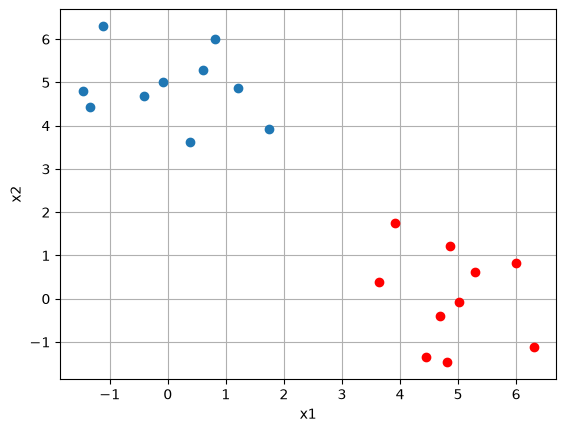

In [206]:
plt.plot(class1_data[:, 0], class1_data[:, 1], 'o')
plt.plot(class2_data[:, 0], class2_data[:, 1], 'ro')
plt.xlabel('x1')
plt.ylabel('x2')
plt.grid()


#### Step 2. 모델 생성

In [207]:
from torch import nn

class MLP(nn.Module) :
    def __init__(self):
        super().__init__()

        self.linear = nn.Sequential(nn.Linear(2, 100),
                                    nn.Sigmoid(),
                                    nn.Linear(100, 1),
                                    nn.Sigmoid()
                                    )
    def forward(self, x):   # nn.Module에서 forward는 자동생성하도록 정의, 이름 동일하게 생성 필요함
        x = self.linear(x)
        return x

In [208]:
# from torch import nn

# class MLP(nn.Module) :
#     def __init__(self):
#         super().__init__()

#         self.linear = nn.Sequential(nn.Linear(2, 100),      # 복잡한 데이터라면 층을 더 많이 생성할 수록 성능이 올라감
#                                     nn.Sigmoid(),
#                                     nn.Linear(100, 100),
#                                     nn.Sigmoid(),
#                                     nn.Linear(100, 100),
#                                     nn.Sigmoid(),
#                                     nn.Linear(100, 1),
#                                     nn.Sigmoid()
#                                     )
#     def forward(self, x):   # nn.Module에서 forward는 자동생성하도록 정의, 이름 동일하게 생성 필요함
#         x = self.linear(x)
#         return x

In [209]:
model = MLP()
print(model)

b = model(torch.randn(5,2))
print(b.shape)
print(b)


MLP(
  (linear): Sequential(
    (0): Linear(in_features=2, out_features=100, bias=True)
    (1): Sigmoid()
    (2): Linear(in_features=100, out_features=1, bias=True)
    (3): Sigmoid()
  )
)
torch.Size([5, 1])
tensor([[0.5768],
        [0.5460],
        [0.5562],
        [0.6298],
        [0.6502]], grad_fn=<SigmoidBackward0>)


#### Step 3. 모델 학습

In [210]:
from torch import optim

In [211]:
LR = 1e-1   # 0.1
EPOCH = 100

optimizer = optim.SGD(model.parameters(), lr=LR)
criterion = nn.BCELoss()

loss_history = []

model.train()   # 학습 모드로 전환
for ep in range(EPOCH):
    
    # 예측값
    y_hat = model(x)
    
    # loss 구하기
    loss = criterion(y_hat, y)

    # update
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    loss_history += [loss.item()]

    # print
    # print(f'Epoch: {ep+1}, train loss: {loss.item():.4f}')
    # print()

Text(0, 0.5, 'Loss')

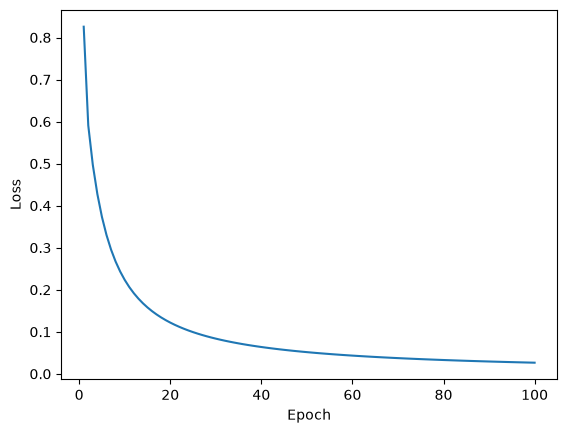

In [212]:
# 학습 곡선
plt.plot(range(1, EPOCH+1), loss_history)
plt.xlabel('Epoch')
plt.ylabel('Loss')